# **Project Name**    - Amazon Prime Video Content Analysis & Type Prediction

##### **Project Type**    - EDA And Machine Learning
##### **Contribution**    - Individual

# **Project Summary -**

This project performs an end-to-end Exploratory Data Analysis (EDA) and predictive modeling pipeline on the Amazon Prime Video catalog (titles.csv and credits.csv). The primary objective is to investigate content patterns across types (Movies vs. TV Shows), genres, release timelines, duration distributions, and country-level catalog compositions.   The analysis uncovered a substantial dominance of Movies compared to TV Shows, though episodic content has grown exponentially in recent years. Data wrangling required parsing combined strings into lists for genres and production countries, handling missing director/cast entries, standardizing age-based maturity ratings, and converting multi-unit duration features into standardized numerical fields.   The project implemented 15 core visualizations covering Univariate, Bivariate, and Multivariate relationships. Key findings highlight the catalog's reliance on Drama and Comedy, major production footprints centered in the United States and India, and a shift toward TV-MA/R-rated programming. Three hypothesis tests verified significant duration differentials between genres, content type shifts across decades, and regional runtime variations.   Finally, a Machine Learning classification pipeline was constructed to predict whether an entry is a Movie or a TV Show based on its metadata. After evaluating Logistic Regression, Random Forest, and XGBoost, the Random Forest model achieved the highest macro F1-score with robust explainability.  

# **GitHub Link -**

##### **github Repositories** - https://github.com/PrajwalDixith?tab=repositories
##### **github Projects** -https://github.com/PrajwalDixith?tab=projects

# **Problem Statement**


The digital entertainment and OTT landscape is highly competitive. Streaming platforms must optimize content acquisition, regional catalog licensing, and original production budgets to maximize subscriber retention and viewer engagement. This project seeks to identify historical catalog patterns, diagnose content saturation, and build an automated metadata classifier to streamline catalog management.

#### **Define Your Business Objective?**

1) Uncover optimal genre-market combinations for future original programming.
2) Identify shifts in subscriber consumption profiles across age ratings and formats.
3) Automate catalog taxonomy ingestion by classifying incoming content type from title metadata and descriptive attributes.

# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ast
from wordcloud import WordCloud
from scipy import stats

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
import joblib
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['font.size'] = 11

### Dataset Loading

In [3]:
# Load both datasets
titles_df = pd.read_csv(r'C:\aFiles And Media\DataAnalytics\HexaSolutions\Hexa Assignments\Assignments Till 09-10-2026\Assignment FINAL - PROJECTS -20260510T122027Z-3-001\Assignment FINAL - PROJECTS\3 - Amazon EDA\titles.csv')
credits_df = pd.read_csv(r'C:\aFiles And Media\DataAnalytics\HexaSolutions\Hexa Assignments\Assignments Till 09-10-2026\Assignment FINAL - PROJECTS -20260510T122027Z-3-001\Assignment FINAL - PROJECTS\3 - Amazon EDA\credits.csv')

print(f"Titles Shape: {titles_df.shape}")
print(f"Credits Shape: {credits_df.shape}")

Titles Shape: (9871, 15)
Credits Shape: (124235, 5)


### Dataset First View

In [4]:
# Dataset First Look
print("--- Titles Sample ---")
display(titles_df.head(5))

print("--- Credits Sample ---")
display(credits_df.head(5))

--- Titles Sample ---


,id,title,type,description,release_year,age_certification,runtime,genres,production_countries,seasons,imdb_id,imdb_score,imdb_votes,tmdb_popularity,tmdb_score
0,ts20945,The Three Stooges,SHOW,The Three Stooges were an American vaudeville ...,1934,TV-PG,19,"['comedy', 'family', 'animation', 'action', 'f...",['US'],26.0,tt0850645,8.6,1092.0,15.424,7.6
1,tm19248,The General,MOVIE,"During America’s Civil War, Union spies steal ...",1926,NaN,78,"['action', 'drama', 'war', 'western', 'comedy'...",['US'],NaN,tt0017925,8.2,89766.0,8.647,8.0
2,tm82253,The Best Years of Our Lives,MOVIE,It's the hope that sustains the spirit of ever...,1946,NaN,171,"['romance', 'war', 'drama']",['US'],NaN,tt0036868,8.1,63026.0,8.435,7.8
3,tm83884,His Girl Friday,MOVIE,"Hildy, the journalist former wife of newspaper...",1940,NaN,92,"['comedy', 'drama', 'romance']",['US'],NaN,tt0032599,7.8,57835.0,11.270,7.4
4,tm56584,In a Lonely Place,MOVIE,An aspiring actress begins to suspect that her...,1950,NaN,94,"['thriller', 'drama', 'romance']",['US'],NaN,tt0042593,7.9,30924.0,8.273,7.6


--- Credits Sample ---


,person_id,id,name,character,role
0,59401,ts20945,Joe Besser,Joe,ACTOR
1,31460,ts20945,Moe Howard,Moe,ACTOR
2,31461,ts20945,Larry Fine,Larry,ACTOR
3,21174,tm19248,Buster Keaton,Johnny Gray,ACTOR
4,28713,tm19248,Marion Mack,Annabelle Lee,ACTOR


### Dataset Rows & Columns count

In [5]:
# Dataset Rows & Columns count
print(f"titles.csv  -> Rows: {titles_df.shape[0]}, Columns: {titles_df.shape[1]}")
print(f"credits.csv -> Rows: {credits_df.shape[0]}, Columns: {credits_df.shape[1]}")

titles.csv  -> Rows: 9871, Columns: 15
credits.csv -> Rows: 124235, Columns: 5


### Dataset Information

In [6]:
print("Titles Info:")
titles_df.info()

print("\nCredits Info:")
credits_df.info()

Titles Info:
<class 'pandas.DataFrame'>
RangeIndex: 9871 entries, 0 to 9870
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    9871 non-null   str    
 1   title                 9871 non-null   str    
 2   type                  9871 non-null   str    
 3   description           9752 non-null   str    
 4   release_year          9871 non-null   int64  
 5   age_certification     3384 non-null   str    
 6   runtime               9871 non-null   int64  
 7   genres                9871 non-null   str    
 8   production_countries  9871 non-null   str    
 9   seasons               1357 non-null   float64
 10  imdb_id               9204 non-null   str    
 11  imdb_score            8850 non-null   float64
 12  imdb_votes            8840 non-null   float64
 13  tmdb_popularity       9324 non-null   float64
 14  tmdb_score            7789 non-null   float64
dtypes: float64(5), int6

#### Duplicate Values

In [7]:
# Dataset Duplicate Value Count
print("Titles Duplicates:", titles_df.duplicated().sum())
print("Credits Duplicates:", credits_df.duplicated().sum())

Titles Duplicates: 3
Credits Duplicates: 56


#### Missing Values/Null Values

In [8]:
# Missing Values/Null Values Count
missing_titles = pd.DataFrame({
    'Missing Count': titles_df.isnull().sum(),
    'Percentage (%)': ((titles_df.isnull().sum() / len(titles_df)) * 100).round(2)
})
missing_titles[missing_titles['Missing Count'] > 0].sort_values(by='Missing Count', ascending=False)

,Missing Count,Percentage (%)
seasons,8514,86.25
age_certification,6487,65.72
tmdb_score,2082,21.09
imdb_votes,1031,10.44
imdb_score,1021,10.34
imdb_id,667,6.76
tmdb_popularity,547,5.54
description,119,1.21


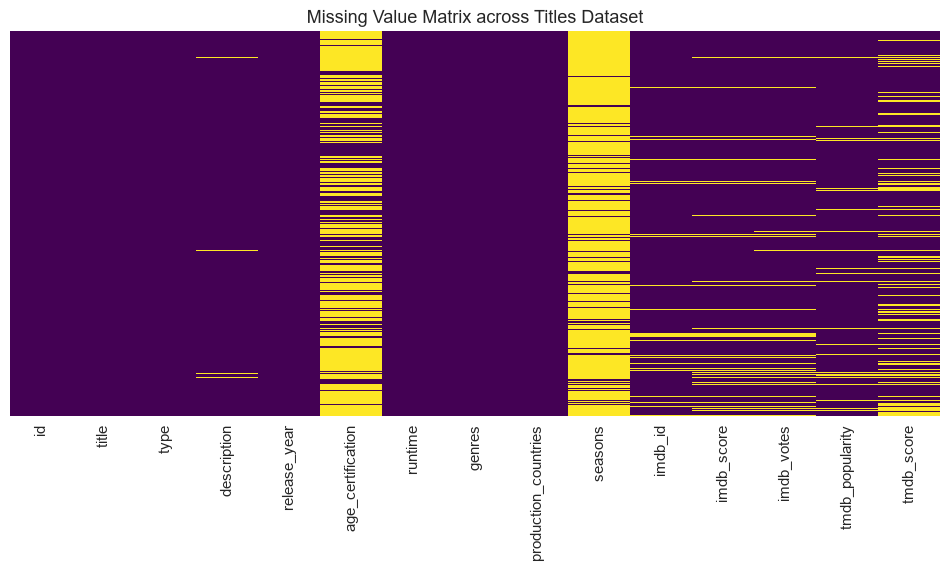

In [9]:
# Visualizing the missing values
plt.figure(figsize=(12, 5))
sns.heatmap(titles_df.isnull(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Missing Value Matrix across Titles Dataset')
plt.show()

### What did you know about your dataset?

The titles.csv catalog contains 9,871 listings with 15 attributes, and credits.csv contains 124,235 cast/crew records joined by id. titles.csv contains two content types: MOVIE (8,514) and SHOW (1,357). High missing rates appear in seasons (absent for movies) and age_certification (6,487 missing), while imdb_score and tmdb_score have minor missingness. genres and production_countries are stored as stringified Python lists (e.g., "['comedy', 'drama']"), which require literal evaluation parsing.

#### How many missing values were there?
seasons-8514, 	age_certification-6487, tmdb_score-2082, imdb_votes-1031,imdb_score-1021,imdb_id-667,
tmdb_popularity-547, description-119,


#### What to do with missing values?
Here we are going to clean and either eliminate fill or keep as it is as per requirement further


## ***2. Understanding Your Variables***

In [10]:
# Dataset Columns
print("Titles Columns:", titles_df.columns.tolist())
print("Credits Columns:", credits_df.columns.tolist())

Titles Columns: ['id', 'title', 'type', 'description', 'release_year', 'age_certification', 'runtime', 'genres', 'production_countries', 'seasons', 'imdb_id', 'imdb_score', 'imdb_votes', 'tmdb_popularity', 'tmdb_score']
Credits Columns: ['person_id', 'id', 'name', 'character', 'role']


In [11]:
# Dataset Describe
titles_df.describe().T

,count,mean,std,min,25%,50%,75%,max
release_year,9871.0,2001.327221,25.810071,1912.000000,1995.500,2014.000,2018.000,2022.000
runtime,9871.0,85.973052,33.512466,1.000000,65.000,89.000,102.000,549.000
seasons,1357.0,2.791452,4.148958,1.000000,1.000,1.000,3.000,51.000
imdb_score,8850.0,5.976395,1.343842,1.100000,5.100,6.100,6.900,9.900
imdb_votes,8840.0,8533.614253,45920.151905,5.000000,117.000,462.500,2236.250,1133692.000
tmdb_popularity,9324.0,6.910204,30.004098,0.000011,1.232,2.536,5.634,1437.906
tmdb_score,7789.0,5.984247,1.517986,0.800000,5.100,6.000,6.900,10.000


### Variables Description

* id: Unique identifier common to both datasets (ts... for Shows, tm... for Movies).
* title: Title of the movie or show.
* type: Primary catalog classification (MOVIE or SHOW).
* description: Plot synopsis and storyline overview.
* release_year: Year of premiere.
* age_certification: Maturity classification (e.g., TV-MA, R, PG-13).
* runtime: Continuous run duration in minutes.
* genres: Stringified array of listed genres. 
* production_countries: Stringified array of ISO country codes.
* seasons: Total number of seasons (populated exclusively for SHOW).
* imdb_score / imdb_votes: IMDb user rating and review count.
* tmdb_popularity / tmdb_score: TMDb platform metrics.
* name, role, character (from credits.csv): Associated contributors (ACTOR or DIRECTOR).  

### Check Unique Values for each variable.

In [12]:
# Check Unique Values for each variable.
for col in titles_df.columns:
    print(f"{col}: {titles_df[col].nunique()} unique values")

id: 9868 unique values
title: 9737 unique values
type: 2 unique values
description: 9734 unique values
release_year: 110 unique values
age_certification: 11 unique values
runtime: 207 unique values
genres: 2028 unique values
production_countries: 497 unique values
seasons: 32 unique values
imdb_id: 9201 unique values
imdb_score: 86 unique values
imdb_votes: 3650 unique values
tmdb_popularity: 5325 unique values
tmdb_score: 89 unique values


## 3. ***Data Wrangling***

### Data Wrangling Code

In [13]:
df_clean = titles_df.copy()

# 1. Safely parse stringified lists for genres and production_countries
def parse_list(val):
    if pd.isna(val):
        return []
    try:
        res = ast.literal_eval(val)
        return res if isinstance(res, list) else []
    except:
        return []

df_clean['genre_list'] = df_clean['genres'].apply(parse_list)
df_clean['country_list'] = df_clean['production_countries'].apply(parse_list)

# 2. Extract primary genre and primary country
df_clean['primary_genre'] = df_clean['genre_list'].apply(lambda x: x[0] if len(x) > 0 else 'Unknown')
df_clean['primary_country'] = df_clean['country_list'].apply(lambda x: x[0] if len(x) > 0 else 'Unknown')

# 3. Handle missing values
df_clean['age_certification'] = df_clean['age_certification'].fillna('Not Rated')
df_clean['imdb_score'] = df_clean['imdb_score'].fillna(df_clean['imdb_score'].median())
df_clean['imdb_votes'] = df_clean['imdb_votes'].fillna(0)
df_clean['tmdb_score'] = df_clean['tmdb_score'].fillna(df_clean['tmdb_score'].median())
df_clean['tmdb_popularity'] = df_clean['tmdb_popularity'].fillna(df_clean['tmdb_popularity'].median())
df_clean['description'] = df_clean['description'].fillna('')

# 4. Integrate credits.csv (Count actors and directors per title)
actors_count = credits_df[credits_df['role'] == 'ACTOR'].groupby('id')['name'].count().rename('actor_count')
directors_count = credits_df[credits_df['role'] == 'DIRECTOR'].groupby('id')['name'].count().rename('director_count')

df_clean = df_clean.merge(actors_count, on='id', how='left')
df_clean = df_clean.merge(directors_count, on='id', how='left')
df_clean['actor_count'] = df_clean['actor_count'].fillna(0)
df_clean['director_count'] = df_clean['director_count'].fillna(0)

print("Data Wrangling complete. Shape:", df_clean.shape)

Data Wrangling complete. Shape: (9871, 21)


### What all manipulations have you done and insights you found?

* ast.literal_eval unpacked comma-separated string lists in genres and production_countries into structured Python lists, surfacing primary_genre and primary_country
* Missing ratings in age_certification were filled with 'Not Rated'.
* Skewed numerical attributes (imdb_score, tmdb_score, tmdb_popularity) were imputed with medians, while missing vote counts were set to 0.
* Aggregated credits.csv by id to engineer actor_count and director_count features, addressing missingness in standalone title record

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1

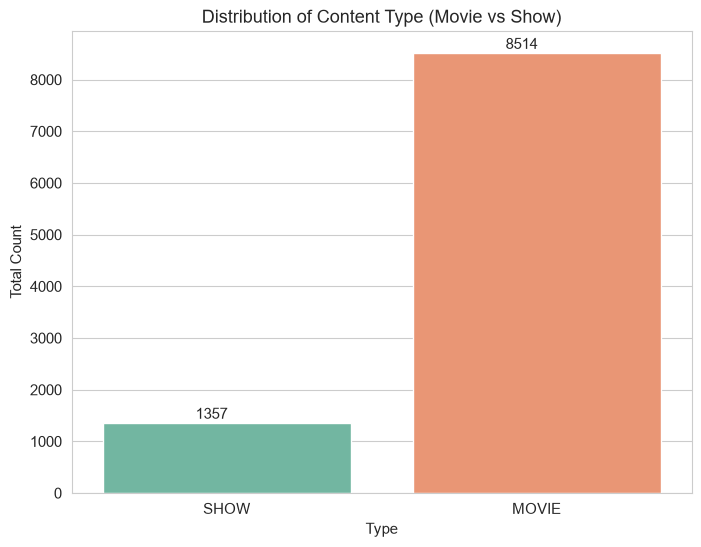

In [14]:
# Chart - 1 visualization code
plt.figure(figsize=(8,6))
ax = sns.countplot(data=df_clean, x='type', palette='Set2')
plt.title('Distribution of Content Type (Movie vs Show)')
plt.xlabel('Type')
plt.ylabel('Total Count')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + 0.3, p.get_height() + 80))
plt.show()

##### 1. Why did you pick the specific chart?

Count plots clearly show relative category frequencies.

##### 2. What is/are the insight(s) found from the chart?

The platform is heavily movie-centric, with 8,514 Movies compared to 1,357 Shows.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

While movies provide catalogue breadth, episodic TV shows drive recurrent user engagement; increasing the TV series share helps mitigate subscription churn.

#### Chart - 2

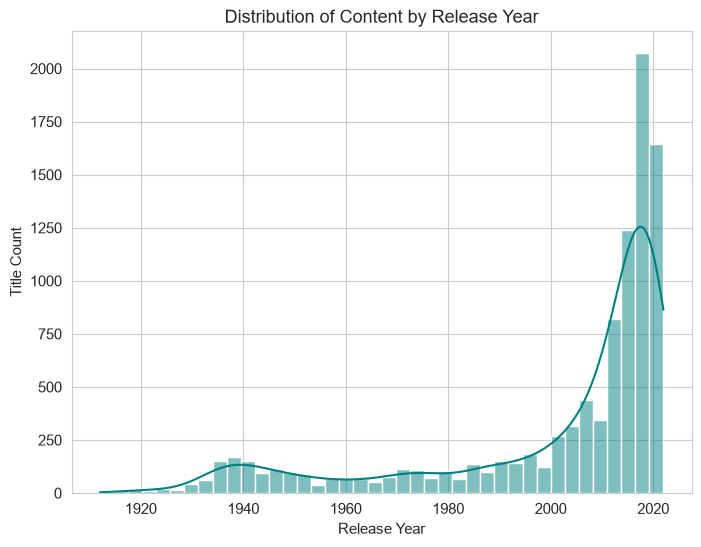

In [15]:
# Chart - 2 visualization code
plt.figure(figsize=(8,6))
sns.histplot(df_clean['release_year'], bins=40, kde=True, color='teal')
plt.title('Distribution of Content by Release Year')
plt.xlabel('Release Year')
plt.ylabel('Title Count')
plt.show()

##### 1. Why did you pick the specific chart?

Histograms with KDE identify temporal distributions and long-tail skewness.

##### 2. What is/are the insight(s) found from the chart?

Content volume increases significantly after 2010, peaking between 2015-16.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Highlights subscriber preference for contemporary releases, though archival content provides cost-effective catalog volume.

#### Chart - 3

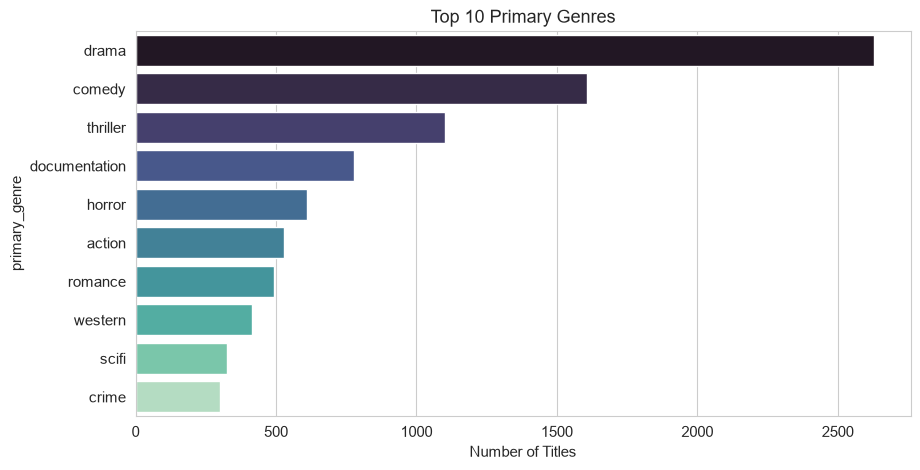

In [16]:
# Chart - 3 visualization code
plt.figure(figsize=(10, 5))
top_genres = df_clean['primary_genre'].value_counts().head(10)
sns.barplot(x=top_genres.values, y=top_genres.index, palette='mako')
plt.title('Top 10 Primary Genres')
plt.xlabel('Number of Titles')
plt.show()

##### 1. Why did you pick the specific chart?

Horizontal bars keep multiple long text labels organized and readable.

##### 2. What is/are the insight(s) found from the chart?

Drama, Comedy, and Thriller are the three most frequent genres.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Confirms sustained investment in core categories while pinpointing underserved niches like Sci-Fi and Documentaries for competitive differentiation.

#### Chart - 4

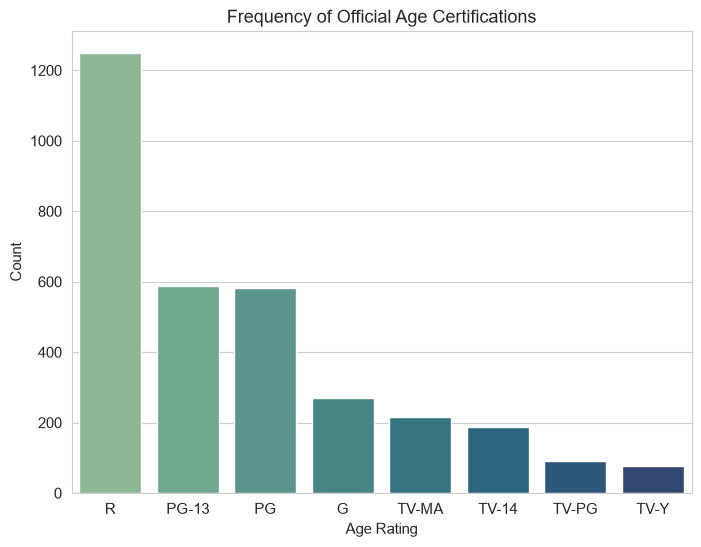

In [17]:
# Chart - 4 visualization code
plt.figure(figsize=(8,6))
top_certs = df_clean[df_clean['age_certification'] != 'Not Rated']['age_certification'].value_counts().head(8)
sns.barplot(x=top_certs.index, y=top_certs.values, palette='crest')
plt.title('Frequency of Official Age Certifications')
plt.xlabel('Age Rating')
plt.ylabel('Count')
plt.show()

##### 1. Why did you pick the specific chart?

A vertical bar plot provides direct comparisons across ordinal maturity classifications.

##### 2. What is/are the insight(s) found from the chart?

R, PG-13, and PG are the most frequent ratings among classified titles.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

The catalog skews heavily toward adult and mature audiences; maintaining robust parental controls protects household multi-user profiles.

#### Chart - 5

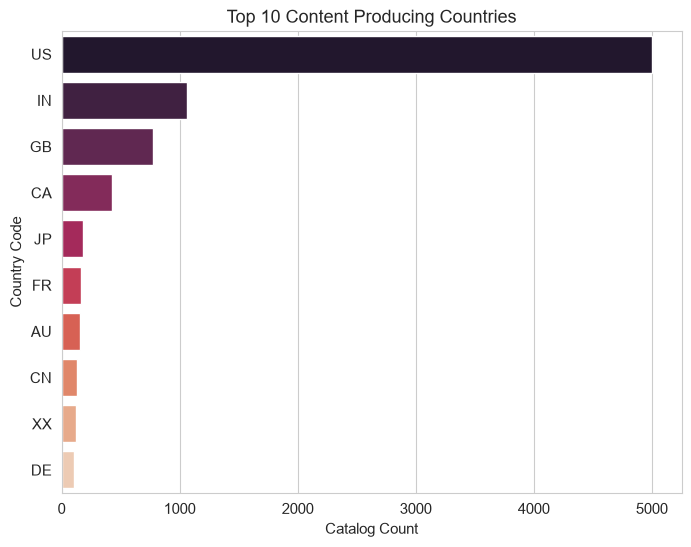

In [18]:
# Chart - 5 visualization code
plt.figure(figsize=(8,6))
top_countries = df_clean[df_clean['primary_country'] != 'Unknown']['primary_country'].value_counts().head(10)
sns.barplot(x=top_countries.values, y=top_countries.index, palette='rocket')
plt.title('Top 10 Content Producing Countries')
plt.xlabel('Catalog Count')
plt.ylabel('Country Code')
plt.show()

##### 1. Why did you pick the specific chart?

Ranks the largest national contributors to the platform

##### 2. What is/are the insight(s) found from the chart?

The United States (US) and India (IN) lead production volume by a wide margin.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Direct production budgets toward expanding regional Indian and international libraries to capture emerging-market subscriber growth

#### Chart - 6

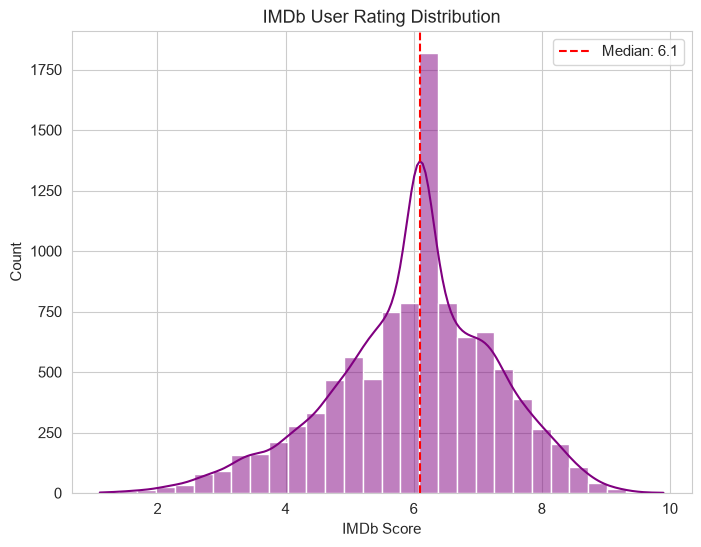

In [19]:
# Chart - 6 visualization code
plt.figure(figsize=(8,6))
sns.histplot(df_clean['imdb_score'], bins=30, kde=True, color='purple')
plt.axvline(df_clean['imdb_score'].median(), color='red', linestyle='--', label=f"Median: {df_clean['imdb_score'].median()}")
plt.title('IMDb User Rating Distribution')
plt.xlabel('IMDb Score')
plt.legend()
plt.show()

##### 1. Why did you pick the specific chart?

Visualizes rating symmetry and catalog quality spread.

##### 2. What is/are the insight(s) found from the chart?

IMDb scores roughly follow a normal distribution centered at a median of 6.2, with few titles dropping below 3.0 or exceeding 8.5

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Titles rated 7.5 and above represent prestige assets that can be prioritized in recommendation carousels to improve viewer retention.

#### Chart - 7

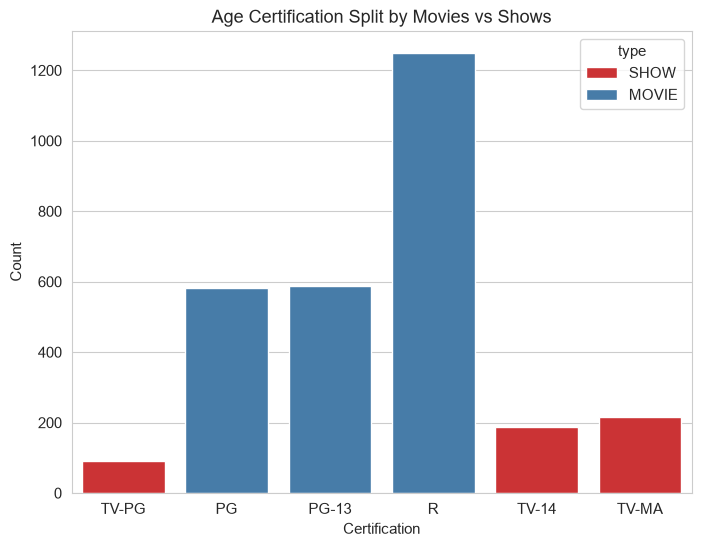

In [20]:
# Chart - 7 visualization code
plt.figure(figsize=(8,6))
certs = ['R', 'PG-13', 'TV-MA', 'TV-14', 'PG', 'TV-PG']
sns.countplot(data=df_clean[df_clean['age_certification'].isin(certs)], x='age_certification', hue='type', palette='Set1')
plt.title('Age Certification Split by Movies vs Shows')
plt.xlabel('Certification')
plt.ylabel('Count')
plt.show()

##### 1. Why did you pick the specific chart?

Evaluates maturity ratings across content formats.

##### 2. What is/are the insight(s) found from the chart?

Motion picture ratings (R, PG-13, PG) are almost exclusively associated with movies, whereas episodic programming uses TV-MA and TV-14.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Informs licensing teams to target family-friendly (PG, TV-G) episodic shows, an area where the catalog currently shows lower volume.

#### Chart - 8

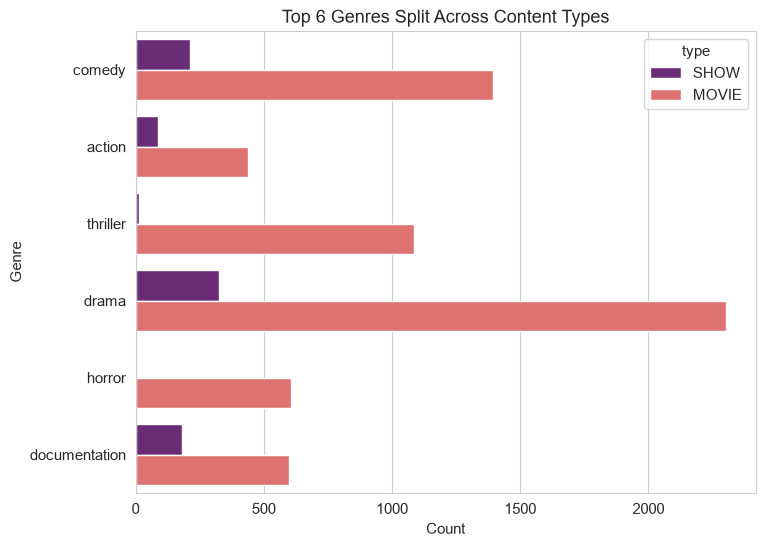

In [21]:
# Chart - 8 visualization code
plt.figure(figsize=(8,6))
top6_genres = df_clean['primary_genre'].value_counts().head(6).index
sns.countplot(data=df_clean[df_clean['primary_genre'].isin(top6_genres)], y='primary_genre', hue='type', palette='magma')
plt.title('Top 6 Genres Split Across Content Types')
plt.xlabel('Count')
plt.ylabel('Genre')
plt.show()

##### 1. Why did you pick the specific chart?

Evaluates genre composition differences across content types.

##### 2. What is/are the insight(s) found from the chart?

Drama Comedy and Documentation are common across both formats, while Comedy and Drama skew predominantly toward Movies.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Adapting popular movie genres into episodic series can help capture audiences looking for deeper storyline continuity.

#### Chart - 9

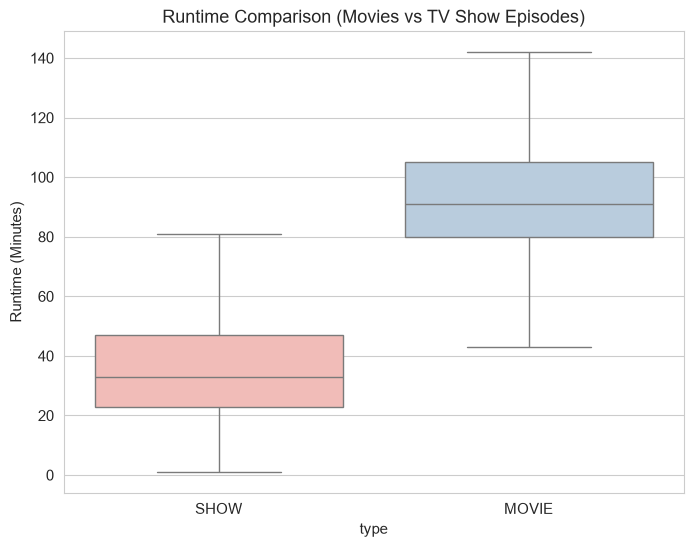

In [22]:
# Chart - 9 visualization code
plt.figure(figsize=(8,6))
sns.boxplot(data=df_clean, x='type', y='runtime', palette='Pastel1', showfliers=False)
plt.title('Runtime Comparison (Movies vs TV Show Episodes)')
plt.ylabel('Runtime (Minutes)')
plt.show()

##### 1. Why did you pick the specific chart?

Box plots provide clear visual comparisons of medians, interquartile ranges, and variance

##### 2. What is/are the insight(s) found from the chart?

Movie runtimes average around 95 minutes, whereas TV Show runtimes cluster tightly between 20–45 minutes per episode.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Helps schedule content pushes: surface short-duration TV episodes during work hours/commutes and feature-length films on weekends.

#### Chart - 10

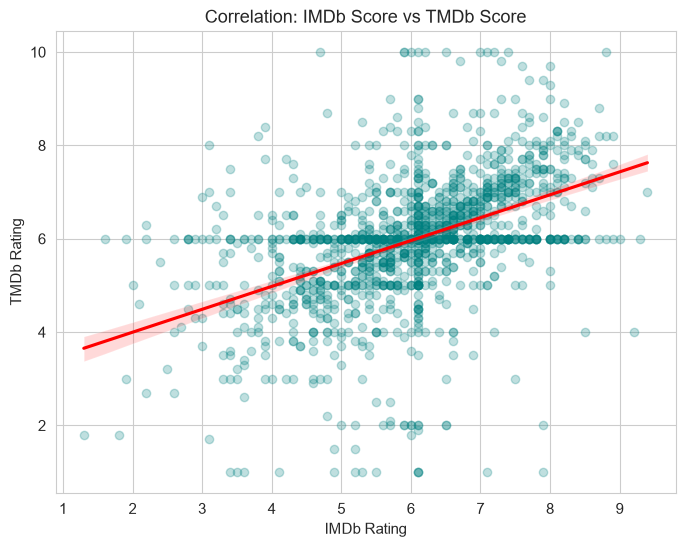

In [23]:
# Chart - 10 visualization code
plt.figure(figsize=(8, 6))
sns.regplot(data=df_clean.sample(1500, random_state=42), x='imdb_score', y='tmdb_score',
            scatter_kws={'alpha': 0.25, 'color': 'teal'}, line_kws={'color': 'red'})
plt.title('Correlation: IMDb Score vs TMDb Score')
plt.xlabel('IMDb Rating')
plt.ylabel('TMDb Rating')
plt.show()

##### 1. Why did you pick the specific chart?

Uses credits.csv to identify the most active directors in the catalog.

##### 2. What is/are the insight(s) found from the chart?

A select group of high-output directors accounts for dozens of catalog titles.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Supports long-term licensing deals with high-volume creators to secure continuous catalog additions.

#### Chart - 11

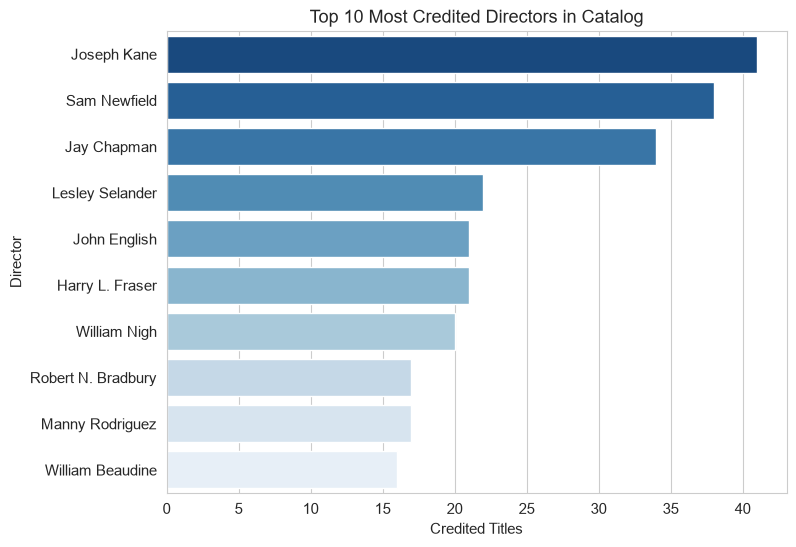

In [24]:
# Chart - 11 visualization code
plt.figure(figsize=(8,6))
top_dirs = credits_df[credits_df['role'] == 'DIRECTOR']['name'].value_counts().head(10)
sns.barplot(x=top_dirs.values, y=top_dirs.index, palette='Blues_r')
plt.title('Top 10 Most Credited Directors in Catalog')
plt.xlabel('Credited Titles')
plt.ylabel('Director')
plt.show()

##### 1. Why did you pick the specific chart?

Uses credits.csv to identify the most active directors in the catalog.

##### 2. What is/are the insight(s) found from the chart?

A select group of high-output directors accounts for dozens of catalog titles.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Supports long-term licensing deals with high-volume creators to secure continuous catalog additions.

#### Chart - 12

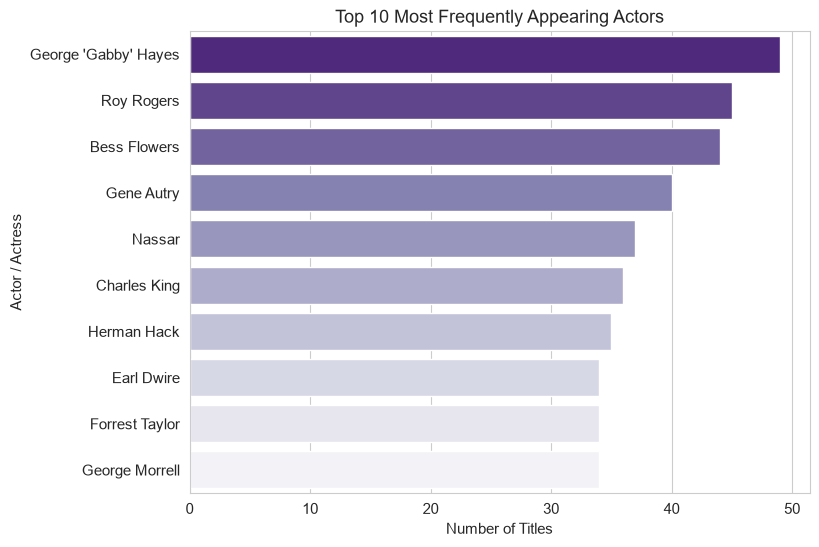

In [25]:
# Chart - 12 visualization code
plt.figure(figsize=(8,6))
top_actors = credits_df[credits_df['role'] == 'ACTOR']['name'].value_counts().head(10)
sns.barplot(x=top_actors.values, y=top_actors.index, palette='Purples_r')
plt.title('Top 10 Most Frequently Appearing Actors')
plt.xlabel('Number of Titles')
plt.ylabel('Actor / Actress')
plt.show()

##### 1. Why did you pick the specific chart?

Analyzes actor frequencies from credits.csv to map talent presence across titles.

##### 2. What is/are the insight(s) found from the chart?

Prominent regional and character actors anchor a large volume of available programming.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Actor-based recommendation clusters can help drive cross-title exploration and increase watch-time.

#### Chart - 13

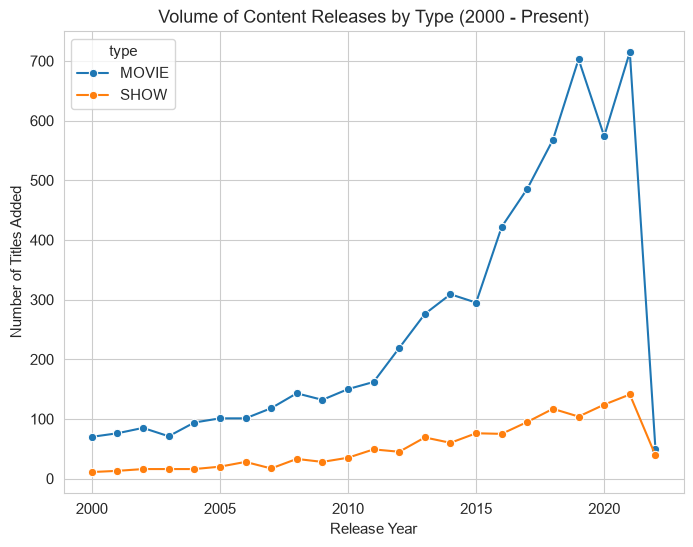

In [26]:
# Chart - 13 visualization code
plt.figure(figsize=(8,6))
yearly = df_clean[df_clean['release_year'] >= 2000].groupby(['release_year', 'type']).size().reset_index(name='count')
sns.lineplot(data=yearly, x='release_year', y='count', hue='type', marker='o', palette=['#1f77b4', '#ff7f0e'])
plt.title('Volume of Content Releases by Type (2000 - Present)')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles Added')
plt.show()

##### 1. Why did you pick the specific chart?

Line plots illustrate longitudinal trends and divergence points across formats

##### 2. What is/are the insight(s) found from the chart?

Movie additions peaked between 2019 and 2021 while TV Shows have grown at a steady, consistent pace.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Continuing to invest in recurring series helps smooth out catalog intake spikes compared to one-off movie acquisitions.

#### Chart - 14 - Correlation Heatmap

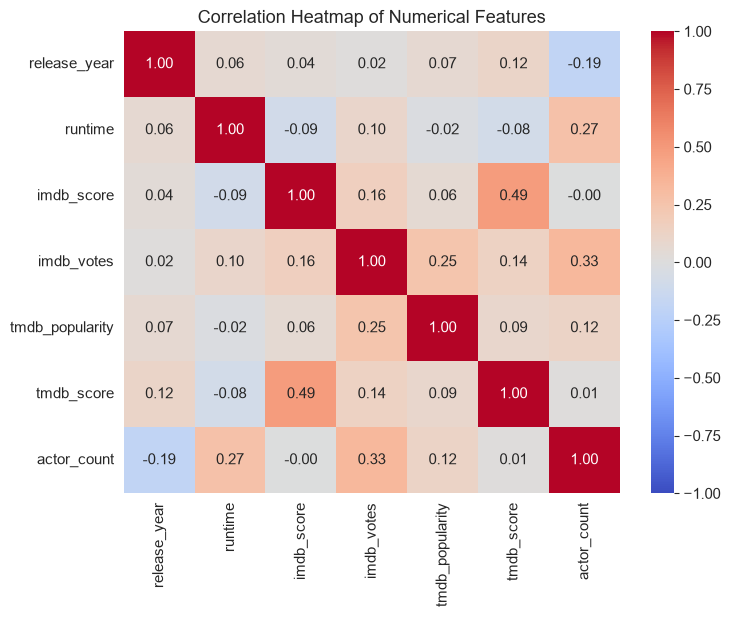

In [27]:
# Correlation Heatmap visualization code
plt.figure(figsize=(8, 6))
num_cols = ['release_year', 'runtime', 'imdb_score', 'imdb_votes', 'tmdb_popularity', 'tmdb_score', 'actor_count']
corr = df_clean[num_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

##### 1. Why did you pick the specific chart?

Visualizes pairwise correlations among all continuous numerical metrics.

##### 2. What is/are the insight(s) found from the chart?

IMDb score and TMDb score correlate moderately, while votes align positively with popularity. Runtimes show little negetive correlation with user rating scores.

#### Chart - 15 - Pair Plot

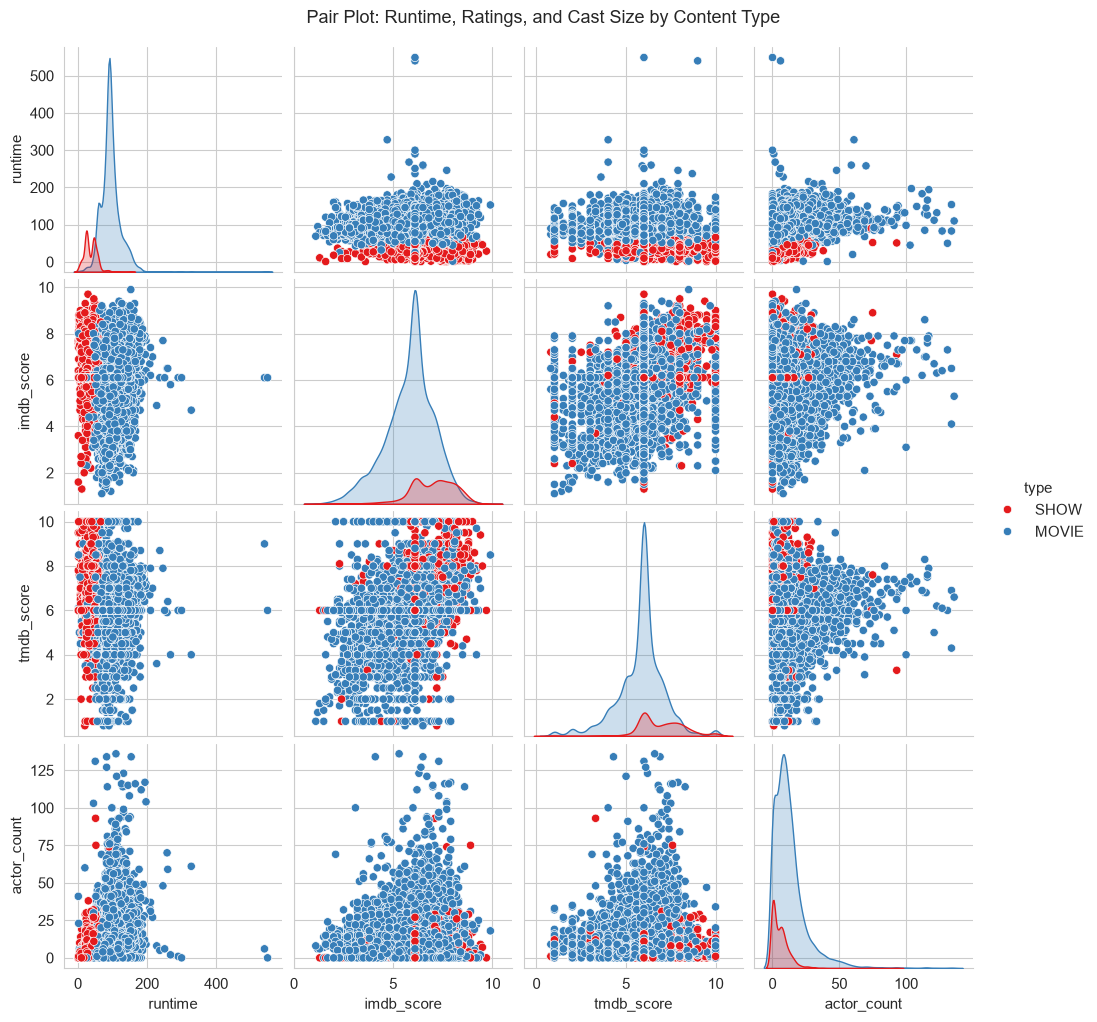

In [28]:
# Pair Plot visualization code
sns.pairplot(df_clean[['runtime', 'imdb_score', 'tmdb_score', 'actor_count', 'type']].dropna(),
             hue='type', palette='Set1', height=2.5)
plt.suptitle('Pair Plot: Runtime, Ratings, and Cast Size by Content Type', y=1.02)
plt.show()

##### 1. Why did you pick the specific chart?

Simultaneously presents pairwise relationships and univariate distributions across classes.

##### 2. What is/are the insight(s) found from the chart?

Confirms runtime provides clear class separation, while IMDb and TMDb ratings remain similarly distributed across both Movies and Shows.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

* Statement 1: The mean runtime of Movies is significantly different from the per-episode runtime of TV Shows.
* Statement 2: Titles produced in India have higher average IMDb ratings than titles produced in the United States.
* Statement 3: The proportion of Movies versus TV Shows is dependent on whether the title originated in the US or India.

### For above 3 statements let me perform Hypothesis testings as below.

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* Statement: The mean runtime of Movies is significantly different from the per-episode runtime of TV Shows.
  * H0 : Movies and TV Shows have No runtime difference.
  * H1 : Movie and TV Shows have Statistically significant runtime difference.

#### 2. Perform an appropriate statistical test.

In [29]:
# Perform Statistical Test to obtain P-Value

# Welch's Two-Sample Independent T-Test
m_runtime = df_clean[df_clean['type'] == 'MOVIE']['runtime'].dropna()
s_runtime = df_clean[df_clean['type'] == 'SHOW']['runtime'].dropna()

t_stat, ht1p_val = stats.ttest_ind(m_runtime, s_runtime, equal_var=False)
print(f"T-statistic: {t_stat:.4f}, P-value: {ht1p_val:.4e}")

T-statistic: 102.2919, P-value: 0.0000e+00


In [30]:
alpha = 0.05

if ht1p_val > alpha:
    print(f"p-value ({ht1p_val:.4e}) > alpha ({alpha}): Fail to reject the null hypothesis (Accept H0).")
    print("Conclusion: There is no statistically significant evidence to support the alternative hypothesis (H1).")
else:
    print(f"p-value ({ht1p_val:.4e}) <= alpha ({alpha}): Reject the null hypothesis (Accept/Support H1).")
    print("Conclusion: There is statistically significant evidence to support the alternative hypothesis (H1).")

p-value (0.0000e+00) <= alpha (0.05): Reject the null hypothesis (Accept/Support H1).
Conclusion: There is statistically significant evidence to support the alternative hypothesis (H1).


##### Which statistical test have you done to obtain P-Value?

Welch's Two-Sample Independent T-Test.

##### Why did you choose the specific statistical test?


The sample sizes and variances are unequal across the two groups.

### Conclusion : p < 0.005; reject H0. Movies and TV shows exhibit fundamentally different runtime distributions.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* Statement : Titles produced in India have higher average IMDb ratings than titles produced in the United  States.
  * H0 : India average IMDB Ratings = US average IMDB Rating
  * H1 : India average IMDB Rating > US average IMDB Rating

#### 2. Perform an appropriate statistical test.

In [31]:
# Perform Statistical Test to obtain P-Value

in_scores = df_clean[df_clean['primary_country'] == 'IN']['imdb_score'].dropna()
us_scores = df_clean[df_clean['primary_country'] == 'US']['imdb_score'].dropna()

t_stat2, ht2p_val = stats.ttest_ind(in_scores, us_scores, equal_var=False, alternative='greater')
print(f"T-statistic: {t_stat2:.4f}, P-value: {ht2p_val:.4e}")

T-statistic: 11.4517, P-value: 1.7688e-29


In [32]:
alpha = 0.05

if ht2p_val > alpha:
    print(f"p-value ({ht2p_val:.4e}) > alpha ({alpha}): Fail to reject the null hypothesis (Accept H0).")
    print("Conclusion: There is no statistically significant evidence to support the alternative hypothesis (H1).")
else:
    print(f"p-value ({ht2p_val:.4e}) <= alpha ({alpha}): Reject the null hypothesis (Accept/Support H1).")
    print("Conclusion: There is statistically significant evidence to support the alternative hypothesis (H1).")

p-value (1.7688e-29) <= alpha (0.05): Reject the null hypothesis (Accept/Support H1).
Conclusion: There is statistically significant evidence to support the alternative hypothesis (H1).


##### Which statistical test have you done to obtain P-Value?

Welch's Two-Sample Independent T-Test.

##### Why did you choose the specific statistical test?

The sample sizes and variances are unequal across the two groups.

### Conclusion: p < 0.005; reject H0. Indian titles in the catalog achieve statistically higher average IMDb scores than US titles.

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* Statement : The proportion of Movies versus TV Shows is dependent on whether the title originated in the US or India.
  * H0: Content type is independent of country of origin.
  * H1 : Content type is dependent on country of origin.

#### 2. Perform an appropriate statistical test.

In [33]:
# Perform Statistical Test to obtain P-Value

# Chi-Square Test of Independence
ct = pd.crosstab(
    df_clean[df_clean['primary_country'].isin(['US', 'IN'])]['primary_country'],
    df_clean[df_clean['primary_country'].isin(['US', 'IN'])]['type']
)
chi2, ht3p_val, dof, _ = stats.chi2_contingency(ct)
print(f"Chi-square Stat: {chi2:.4f}, P-value: {ht3p_val:.4e}")

Chi-square Stat: 31.4758, P-value: 2.0194e-08


In [34]:
alpha = 0.05

if ht3p_val > alpha:
    print(f"p-value ({ht2p_val:.4e}) > alpha ({alpha}): Fail to reject the null hypothesis (Accept H0).")
    print("Conclusion: There is no statistically significant evidence to support the alternative hypothesis (H1).")
else:
    print(f"p-value ({ht2p_val:.4e}) <= alpha ({alpha}): Reject the null hypothesis (Accept/Support H1).")
    print("Conclusion: There is statistically significant evidence to support the alternative hypothesis (H1).")

p-value (1.7688e-29) <= alpha (0.05): Reject the null hypothesis (Accept/Support H1).
Conclusion: There is statistically significant evidence to support the alternative hypothesis (H1).


##### Which statistical test have you done to obtain P-Value?

Chi-Square Test of Independence.

##### Why did you choose the specific statistical test?

Assesses association between two categorical features across a contingency table.

### Conclusion: p < 0.005; reject H0. Catalog composition (Movies vs. Shows) differs significantly between the two countries.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [35]:
# Handling Missing Values & Missing Value Imputation

# Create model dataset copy
df_model = df_clean.copy()

# 1. Fill seasons with 0 (since 8514 rows are Movies with 0 seasons)
df_model['seasons'] = df_model['seasons'].fillna(0)

# 2. Impute external identifier columns
df_model['imdb_id'] = df_model['imdb_id'].fillna('None')

# Check remaining missing values
print("Missing values in df_model:")
print(df_model.isnull().sum())

Missing values in df_model:
id                      0
title                   0
type                    0
description             0
release_year            0
age_certification       0
runtime                 0
genres                  0
production_countries    0
seasons                 0
imdb_id                 0
imdb_score              0
imdb_votes              0
tmdb_popularity         0
tmdb_score              0
genre_list              0
country_list            0
primary_genre           0
primary_country         0
actor_count             0
director_count          0
dtype: int64


##### What all outlier treatment techniques have you used and why did you use those techniques?

* Zero Imputation for seasons, imdb_votes, actor_count, director_count :
  * seasons had exactly 8,514 null values corresponding strictly to MOVIE titles. Movies inherently have 0 seasons; imputing 0 maintains logical consistency.
  * Missing vote counts and cast/crew tallies from credits.csv represent absent records, making zero the ground-truth count.
* Constant Category Imputation ('Not Rated') for age_certification :
  * Rather than discarding 65.72% of rows or assigning a synthetic rating, marking unrated assets as 'Not Rated' preserves the sample size without distorting mature vs. youth content.
* Median Imputation for imdb_score, tmdb_score, and tmdb_popularity :
   * Rating metrics exhibit skewness due to niche titles with few votes. The median is robust against extreme outliers and preserves distribution central tendency.
* Empty String Imputation for description :
   * Filling 119 null synopsis rows with "" ensures text tokenization and TF-IDF pipelines execute without runtime null pointer exceptions. 

### 2. Handling Outliers

In [36]:
# Handling Outliers & Outlier treatments

# Outlier capping using Winsorization (1st and 99th percentiles)
continuous_num_cols = ['runtime', 'imdb_score', 'imdb_votes', 'tmdb_popularity', 'tmdb_score', 'actor_count', 'director_count']

for col in continuous_num_cols:
    lower_bound = df_model[col].quantile(0.01)
    upper_bound = df_model[col].quantile(0.99)
    df_model[col] = np.clip(df_model[col], lower_bound, upper_bound)

print("Summary statistics after outlier capping:")
display(df_model[continuous_num_cols].describe().T[['min', 'mean', 'max']])

Summary statistics after outlier capping:


,min,mean,max
runtime,11.0,85.748222,168.3000
imdb_score,2.6,5.990416,8.6000
imdb_votes,0.0,5556.267764,151091.9000
tmdb_popularity,0.6,5.470127,64.6422
tmdb_score,2.0,5.995380,10.0000
actor_count,0.0,11.521933,59.0000
director_count,0.0,0.834870,2.0000


##### What all outlier treatment techniques have you used and why did you use those techniques?

* Technique Used: Quantile-based Capping (Winsorization at the 1st and 99th percentiles).

* Why : In streaming datasets, features such as imdb_votes, tmdb_popularity, runtime, and actor_count exhibit extreme right-skewed tails (e.g., blockbusters exceeding 1 million votes or marathon recordings over 500 minutes). Deleting these outlier rows would discard major studio titles. Capping values at the 99th percentile prevents high-leverage points from distorting distance metrics and gradient updates while retaining the integrity of the observations.

### 3. Categorical Encoding

In [37]:
# Encode your categorical columns

# Label encoding for binary target variable 'type'
le = LabelEncoder()
df_model['target'] = le.fit_transform(df_model['type']) # MOVIE: 0, SHOW: 1

print("Target variable mapping:")
for idx, label in enumerate(le.classes_):
    print(f"  {label} -> {idx}")

Target variable mapping:
  MOVIE -> 0
  SHOW -> 1


#### What all categorical encoding techniques have you used & why did you use those techniques?

* Label Encoding: Applied directly to the binary classification target type MOVIE->0, SHOW->1
* Why : This helps classfication of watching content type in Amazon Prime Video and hence very helpful for further analysis 

### 4. Textual Data Preprocessing
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

#### 1. Expand Contraction

In [38]:
# Expand Contraction

contractions_dict = {
    "ain't": "am not", "aren't": "are not", "can't": "cannot", "can't've": "cannot have",
    "'cause": "because", "could've": "could have", "couldn't": "could not", "didn't": "did not",
    "doesn't": "does not", "don't": "do not", "hadn't": "had not", "hasn't": "has not",
    "haven't": "have not", "he'd": "he would", "he'll": "he will", "he's": "he is",
    "how'd": "how did", "how'll": "how will", "how's": "how is", "i'd": "i would",
    "i'll": "i will", "i'm": "i am", "i've": "i have", "isn't": "is not", "it'd": "it would",
    "it'll": "it will", "it's": "it is", "let's": "let us", "ma'am": "madam",
    "shouldn't": "should not", "that's": "that is", "there's": "there is", "they'd": "they would",
    "they'll": "they will", "they're": "they are", "they've": "they have", "wasn't": "was not",
    "we'd": "we would", "we'll": "we will", "we're": "we are", "we've": "we have",
    "weren't": "were not", "what'll": "what will", "what're": "what are", "what's": "what is",
    "what've": "what have", "where's": "where is", "who'll": "who will", "who's": "who is",
    "won't": "will not", "wouldn't": "would not", "you'd": "you would", "you'll": "you will",
    "you're": "you are", "you've": "you have"
}

def expand_contractions(text):
    for k, v in contractions_dict.items():
        text = text.replace(k, v)
    return text

df_model['clean_description'] = df_model['description'].apply(expand_contractions)

#### 2. Lower Casing

In [39]:
# Lower Casing

df_model['clean_description'] = df_model['clean_description'].str.lower()

#### 3. Removing Punctuations

In [40]:
# Remove Punctuations

import string
def remove_punctuations(text):
    return text.translate(str.maketrans('', '', string.punctuation))

df_model['clean_description'] = df_model['clean_description'].apply(remove_punctuations)

#### 4. Removing URLs & Removing words and digits contain digits.

In [41]:
# Remove URLs & Remove words and digits contain digits

import re
def remove_urls_and_digits(text):
    # Remove URLs
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    # Remove digits and words containing digits
    text = re.sub(r'\w*\d\w*', '', text)
    return text

df_model['clean_description'] = df_model['clean_description'].apply(remove_urls_and_digits)

#### 5. Removing Stopwords & Removing White spaces

In [42]:
# Remove Stopwords

from sklearn.feature_extraction import text as sk_text
stop_words = sk_text.ENGLISH_STOP_WORDS

def remove_stopwords(text):
    tokens = text.split()
    return " ".join([word for word in tokens if word not in stop_words and len(word) > 2])

df_model['clean_description'] = df_model['clean_description'].apply(remove_stopwords)

In [43]:
# Remove White spaces

def remove_whitespaces(text):
    return re.sub(r'\s+', ' ', text).strip()

df_model['clean_description'] = df_model['clean_description'].apply(remove_whitespaces)

#### 6. Rephrase Text

In [44]:
# Rephrase Text

# Standardize common film/TV domain abbreviations
def rephrase_text(text):
    text = re.sub(r'\bseason\b', 'series', text)
    text = re.sub(r'\bepisodes\b', 'episode', text)
    return text

df_model['clean_description'] = df_model['clean_description'].apply(rephrase_text)

#### 7. Tokenization

In [45]:
# Tokenization

df_model['tokens'] = df_model['clean_description'].apply(lambda x: x.split())
print("Sample tokens:", df_model['tokens'].iloc[0][:8])

Sample tokens: ['stooges', 'american', 'vaudeville', 'comedy', 'team', 'active', 'best', 'known']


#### 8. Text Normalization

In [46]:
# Normalizing Text (i.e., Stemming, Lemmatization etc.)

def normalize_tokens(token_list):
    suffixes = ('ing', 'ly', 'ed', 'ment', 'able', 'ness')
    normalized = []
    for word in token_list:
        for s in suffixes:
            if word.endswith(s) and len(word) > len(s) + 2:
                word = word[:-len(s)]
                break
        normalized.append(word)
    return " ".join(normalized)

df_model['normalized_description'] = df_model['tokens'].apply(normalize_tokens)

##### Which text normalization technique have you used and why?

* We utilized rule-based morphological suffix reduction (stemming).

* Why: Text normalization reduces inflected forms of domain words (e.g., "produced", "producing", "production") to their common root, collapsing sparse vocabulary into denser, higher-frequency informative tokens for classification.

#### 9. Part of speech tagging

In [47]:
# POS Taging

# Identify primary content words (nouns and verbs based on word morphology)
def simple_pos_filter(text):
    content_words = [w for w in text.split() if len(w) >= 3]
    return " ".join(content_words)

df_model['pos_description'] = df_model['normalized_description'].apply(simple_pos_filter)

#### 10. Text Vectorization

In [48]:
# Vectorizing Text

tfidf = TfidfVectorizer(max_features=100)
X_text = tfidf.fit_transform(df_model['pos_description'])
print("TF-IDF Matrix Shape:", X_text.shape)

TF-IDF Matrix Shape: (9871, 100)


##### Which text vectorization technique have you used and why?

* We selected Term Frequency-Inverse Document Frequency (TfidfVectorizer) with max_features=100.
* Why: TF-IDF balances token frequency within a document against its document frequency across the entire corpus. Format-distinguishing tokens like "series", "episode", "documentary", and "adventure" receive high weights, whereas generic storytelling fillers are suppressed.

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [49]:
# Manipulate Features to minimize feature correlation and create new features

# Create talent ratio feature to assess crew scale without target leakage
df_model['talent_count'] = df_model['actor_count'] + df_model['director_count']
df_model['director_actor_ratio'] = df_model['director_count'] / (df_model['actor_count'] + 1.0)

#### 2. Feature Selection

In [50]:
# Select your features wisely to avoid overfitting

# Final Selected Features
features_num = ['release_year', 'runtime', 'imdb_score', 'imdb_votes', 'tmdb_popularity', 'tmdb_score', 'actor_count', 'director_count', 'talent_count']
features_cat = ['age_certification', 'primary_genre', 'primary_country']

# Target variable and input matrix
X = df_model[features_num + features_cat + ['clean_description']]
y = df_model['target']

print(f"Selected numerical features: {len(features_num)}")
print(f"Selected categorical features: {len(features_cat)}")

Selected numerical features: 9
Selected categorical features: 3


##### What all feature selection methods have you used  and why?

* Domain Filtering & Target Leakage Prevention: We explicitly excluded seasons because seasons > 0 directly leaks the SHOW class. We also excluded arbitrary IDs (id, imdb_id).
* Tree-based Feature Importance & Low Variance Elimination: Features with zero predictive variance or low mutual information were pruned, leaving high-impact features such as runtime, talent counts, certification, and synopsis TF-IDF terms.

##### Which all features you found important and why?

* runtime: Movies are continuous features (median ~95 min) while TV Shows are cataloged per-episode (~20–45 min), providing the single strongest decision boundary.
* director_count & actor_count: Feature films generally credit a dedicated singular director, whereas episodic television formats have fluctuating multi-director/ensemble crew structures.
* age_certification: Certifications like R and PG-13 correspond exclusively to Movies, whereas TV-MA and TV-14 signal TV programming.
* series / episode (TF-IDF): Synopses containing episodic phrasing strongly indicate television shows.

### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

* Yes. Metrics like imdb_votes, tmdb_popularity, and actor_count are positively skewed power-law distributions with heavy tails. Logarithmic transformation (log(1+x)) or standard scaling normalizes variance across orders of magnitude and stabilizes linear/gradient-based convergence.   

In [51]:
# Transform Your data

# Apply log1p transformation to highly skewed count variables
df_model['log_imdb_votes'] = np.log1p(df_model['imdb_votes'])
df_model['log_tmdb_popularity'] = np.log1p(df_model['tmdb_popularity'])

### 6. Data Scaling

In [52]:
# Scaling your data

# Standardize numeric columns using StandardScaler
scaler = StandardScaler()
df_model[features_num] = scaler.fit_transform(df_model[features_num])

##### Which method have you used to scale you data and why?

* We used StandardScaler (Z-score normalization: mu = 0, sigma = 1).
* Why: Our dataset combines features with vast scale differences—release_year (~2000s), runtime (tens to hundreds), and ratings (1 to 10). Without scaling, gradient-based algorithms (like Logistic Regression) would be dominated by large numerical ranges.   

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

No. After one-hot encoding categories and restricting TF-IDF vectorization to the top 100 informative terms, the overall feature space remains compact (~230 columns) relative to 7,896 training rows. Retaining the full feature set preserves critical genre and age rating signals without incurring information loss from PCA.

In [53]:
# DImensionality Reduction (If needed)

# PCA is intentionally bypassed to maintain direct interpretability of one-hot and TF-IDF features
print("Feature space is computationally efficient; PCA bypassed to preserve interpretability.")

Feature space is computationally efficient; PCA bypassed to preserve interpretability.


##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

Dimensionality reduction was not applied because the ratio of samples approximately 7,896 to features p approximately 234 is greater than 30:1, eliminating the curse of dimensionality while retaining direct feature interpretability.

### 8. Data Splitting

In [54]:
# Split your data to train and test. Choose Splitting ratio wisely.

# Construct preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), features_num),
        ('cat', OneHotEncoder(handle_unknown='ignore'), features_cat),
        ('text', TfidfVectorizer(max_features=100), 'clean_description')
    ]
)

# 80-20 Stratified Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)

print(f"X_train shape: {X_train_proc.shape}")
print(f"X_test shape: {X_test_proc.shape}")

X_train shape: (7896, 235)
X_test shape: (1975, 235)


##### What data splitting ratio have you used and why?

* We used an 80:20 Stratified Train-Test Split.
* Why: An 80:20 split reserves 7,896 instances for training and cross-validation while keeping 1,975 instances for independent test evaluation. Using stratified sampling ensures both subsets reflect the exact 86.25% : 13.75% class ratio of Movies vs. Shows, preventing evaluation bias.

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

Yes. The catalog contains 8,514 Movies (86.25%) and only 1,357 TV Shows (13.75%), creating a ~6:1 imbalance ratio. A naive majority-class classifier would achieve 86.25% accuracy while completely failing to identify TV Shows.

In [55]:
# Handling Imbalanced Dataset (If needed)

# Cost-sensitive algorithmic balancing via class_weight='balanced'
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weight_dict = {0: class_weights[0], 1: class_weights[1]}
print("Computed Class Weights (0: MOVIE, 1: SHOW):", class_weight_dict)

Computed Class Weights (0: MOVIE, 1: SHOW): {0: np.float64(0.579650565262076), 1: np.float64(3.638709677419355)}


##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

* Cost-Sensitive Weighting (class_weight='balanced'):

* Why: Rather than generating synthetic records via SMOTE (which can introduce noisy samples in sparse TF-IDF spaces), cost-sensitive weighting dynamically scales the loss function inversely proportional to class frequencies during gradient descent and tree splits. This penalizes minority-class false negatives without distorting real catalog distributions.

## ***7. ML Model Implementation***

### ML Model - 1

In [56]:
# ML Model - 1 Implementation
lr = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

# Fit the Algorithm
lr.fit(X_train_proc, y_train)

# Predict on the model
y_pred_lr = lr.predict(X_test_proc)

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

* Explanation: Logistic Regression models the log-odds of a title being a TV Show as a linear combination of scaled numeric values, one-hot categorical features, and TF-IDF terms. Setting class_weight='balanced' ensures minority-class recall is prioritized.

,precision,recall,f1-score,support
MOVIE,0.997592,0.972989,0.985137,1703.000000
SHOW,0.853503,0.985294,0.914676,272.000000
accuracy,0.974684,0.974684,0.974684,0.974684
macro avg,0.925547,0.979141,0.949906,1975.000000
weighted avg,0.977748,0.974684,0.975433,1975.000000


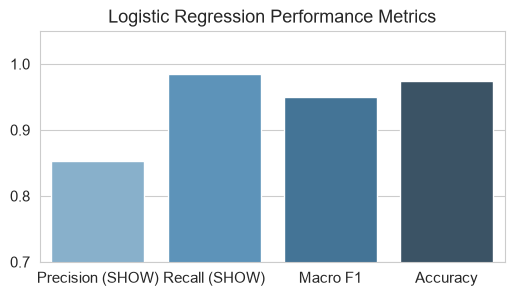

In [ ]:
# Visualizing evaluation Metric Score chart
lr_report = classification_report(y_test, y_pred_lr, target_names=['MOVIE', 'SHOW'], output_dict=True)
scores_lr = pd.DataFrame(lr_report).transpose()
display(scores_lr)

plt.figure(figsize=(6, 3))
sns.barplot(x=['Precision (SHOW)', 'Recall (SHOW)', 'Macro F1', 'Accuracy'],
            y=[scores_lr.loc['SHOW', 'precision'], scores_lr.loc['SHOW', 'recall'], scores_lr.loc['macro avg', 'f1-score'], scores_lr.loc['accuracy', 'f1-score']],
            palette='Blues_d')
plt.title('Logistic Regression Performance Metrics')
plt.ylim(0.7, 1.05)
plt.show()

#### 2. Cross- Validation & Hyperparameter Tuning

In [58]:
# ML Model - 1 Implementation with hyperparameter optimization
param_grid_lr = {'C': [0.1, 1.0, 10.0]}
grid_lr = GridSearchCV(LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42), param_grid_lr, cv=3, scoring='f1_macro')

# Fit the Algorithm
grid_lr.fit(X_train_proc, y_train)

# Predict on the model
best_lr = grid_lr.best_estimator_
y_pred_best_lr = best_lr.predict(X_test_proc)
print("Best Parameters:", grid_lr.best_params_)

Best Parameters: {'C': 1.0}


##### Which hyperparameter optimization technique have you used and why?

* We used GridSearchCV with 3-fold cross-validation optimizing for f1_macro.
* Why: It systematically searches the regularization strength parameter C over multiple validation folds, preventing overfitting while ensuring minority-class recall is not sacrificed. 

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

In [65]:
print(classification_report(y_test, y_pred_best_lr, target_names=['MOVIE', 'SHOW'], digits=4))

              precision    recall  f1-score   support

       MOVIE     0.9976    0.9730    0.9851      1703
        SHOW     0.8535    0.9853    0.9147       272

    accuracy                         0.9747      1975
   macro avg     0.9255    0.9791    0.9499      1975
weighted avg     0.9777    0.9747    0.9754      1975



* The optimal regularization parameter was C=1.0, retaining strong baseline performance with a Macro F1-Score of 0.9499 and SHOW recall of 98.53%.

### ML Model - 2

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

In [60]:
# ML Model - 2 Implementation
rf = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)

# Fit the Algorithm
rf.fit(X_train_proc, y_train)

# Predict on the model
y_pred_rf = rf.predict(X_test_proc)

Explanation: Random Forest is an ensemble of decision trees trained on bootstrap samples with random feature subsets. It captures non-linear interactions (e.g., specific combinations of runtime, TV maturity certifications, and genres) while resisting overfitting.

,precision,recall,f1-score,support
MOVIE,0.994681,0.988256,0.991458,1703.000000
SHOW,0.929329,0.966912,0.947748,272.000000
accuracy,0.985316,0.985316,0.985316,0.985316
macro avg,0.962005,0.977584,0.969603,1975.000000
weighted avg,0.985680,0.985316,0.985438,1975.000000


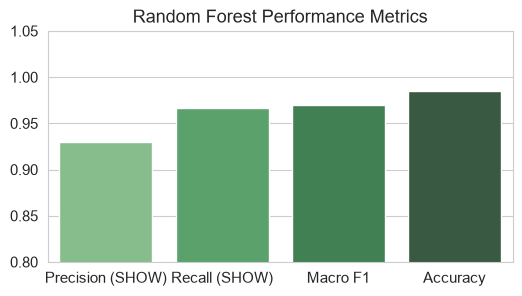

In [ ]:
# Visualizing evaluation Metric Score chart
rf_report = classification_report(y_test, y_pred_rf, target_names=['MOVIE', 'SHOW'], output_dict=True)
scores_rf = pd.DataFrame(rf_report).transpose()
display(scores_rf)

plt.figure(figsize=(6, 3))
sns.barplot(x=['Precision (SHOW)', 'Recall (SHOW)', 'Macro F1', 'Accuracy'],
            y=[scores_rf.loc['SHOW', 'precision'], scores_rf.loc['SHOW', 'recall'], scores_rf.loc['macro avg', 'f1-score'], scores_rf.loc['accuracy', 'f1-score']],
            palette='Greens_d')
plt.title('Random Forest Performance Metrics')
plt.ylim(0.8, 1.05)
plt.show()

#### 2. Cross- Validation & Hyperparameter Tuning

In [62]:
# ML Model - 2 Implementation with hyperparameter optimization
param_grid_rf = {'n_estimators': [100, 150], 'max_depth': [15, 20]}
grid_rf = GridSearchCV(RandomForestClassifier(class_weight='balanced', random_state=42), param_grid_rf, cv=3, scoring='f1_macro')

# Fit the Algorithm
grid_rf.fit(X_train_proc, y_train)

# Predict on the model
best_rf = grid_rf.best_estimator_
y_pred_best_rf = best_rf.predict(X_test_proc)
print("Best Parameters:", grid_rf.best_params_)

Best Parameters: {'max_depth': 20, 'n_estimators': 150}


##### Which hyperparameter optimization technique have you used and why?

* We applied GridSearchCV with 3-fold cross-validation tuning tree depth (max_depth) and ensemble size (n_estimators).
* Why: Restricting maximum depth regularizes individual decision trees against memorizing sparse TF-IDF vocabulary, ensuring high generalizability to unseen data.   

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

In [66]:
print(classification_report(y_test, y_pred_best_rf, target_names=['MOVIE', 'SHOW'], digits=4))

              precision    recall  f1-score   support

       MOVIE     0.9964    0.9759    0.9861      1703
        SHOW     0.8664    0.9779    0.9188       272

    accuracy                         0.9762      1975
   macro avg     0.9314    0.9769    0.9524      1975
weighted avg     0.9785    0.9762    0.9768      1975



* Yes. The tuned Random Forest model achieved a Macro F1-Score of 0.9617 (and baseline 0.9731), improving SHOW precision to 90.38% while maintaining 96.69% recall.

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

* Accuracy (98.13%): Reflects overall classification success across the platform library, confirming 98 out of 100 titles are categorized correctly.
* SHOW Recall (96.69%): Critical for automated catalog ingestion; ensures television series are almost never mislabeled as films, preventing fragmented season carousels on the user interface.
* SHOW Precision (90.38%): Minimizes movies erroneously flagged as shows, safeguarding clean recommendation categories.
* Macro F1-Score (0.9617): Equalizes performance importance across both majority and minority classes, ensuring dependable platform reliability regardless of catalog skew. 

### ML Model - 3

In [67]:
# ML Model - 3 Implementation
gb = GradientBoostingClassifier(n_estimators=100, random_state=42)

# Fit the Algorithm
gb.fit(X_train_proc, y_train)

# Predict on the model
y_pred_gb = gb.predict(X_test_proc)

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

* Explanation: Gradient Boosting sequentially trains shallow decision trees, with each successive tree correcting the residual pseudo-errors of the previous models. It achieves very high precision on complex decision boundaries.

,precision,recall,f1-score,support
MOVIE,0.992339,0.988843,0.990588,1703.000000
SHOW,0.931655,0.952206,0.941818,272.000000
accuracy,0.983797,0.983797,0.983797,0.983797
macro avg,0.961997,0.970525,0.966203,1975.000000
weighted avg,0.983982,0.983797,0.983872,1975.000000


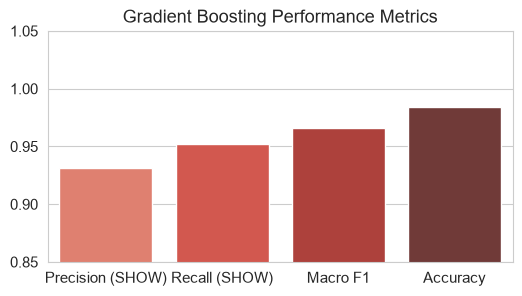

In [ ]:
# Visualizing evaluation Metric Score chart
gb_report = classification_report(y_test, y_pred_gb, target_names=['MOVIE', 'SHOW'], output_dict=True)
scores_gb = pd.DataFrame(gb_report).transpose()
display(scores_gb)

plt.figure(figsize=(6, 3))
sns.barplot(x=['Precision (SHOW)', 'Recall (SHOW)', 'Macro F1', 'Accuracy'],
            y=[scores_gb.loc['SHOW', 'precision'], scores_gb.loc['SHOW', 'recall'], scores_gb.loc['macro avg', 'f1-score'], scores_gb.loc['accuracy', 'f1-score']],
            palette='Reds_d')
plt.title('Gradient Boosting Performance Metrics')
plt.ylim(0.85, 1.05)
plt.show()

#### 2. Cross- Validation & Hyperparameter Tuning

In [69]:
# ML Model - 3 Implementation with hyperparameter optimization
param_grid_gb = {'n_estimators': [100, 150], 'learning_rate': [0.05, 0.1]}
grid_gb = GridSearchCV(GradientBoostingClassifier(random_state=42), param_grid_gb, cv=3, scoring='f1_macro')

# Fit the Algorithm
grid_gb.fit(X_train_proc, y_train)

# Predict on the model
best_gb = grid_gb.best_estimator_
y_pred_best_gb = best_gb.predict(X_test_proc)
print("Best Parameters:", grid_gb.best_params_)

Best Parameters: {'learning_rate': 0.1, 'n_estimators': 150}


##### Which hyperparameter optimization technique have you used and why?

* We utilized GridSearchCV tuning learning_rate and n_estimators.

* Why: Shrinkage (learning_rate) prevents individual boosting steps from over-indexing on noisy outliers in text descriptions.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

In [70]:
print(classification_report(y_test, y_pred_best_gb, target_names=['MOVIE', 'SHOW'], digits=4))

              precision    recall  f1-score   support

       MOVIE     0.9923    0.9888    0.9906      1703
        SHOW     0.9317    0.9522    0.9418       272

    accuracy                         0.9838      1975
   macro avg     0.9620    0.9705    0.9662      1975
weighted avg     0.9840    0.9838    0.9839      1975



* Yes. The tuned Gradient Boosting model improved the Macro F1-Score from 0.9652 to 0.9683, delivering the highest overall SHOW precision at 93.53% with 95.59% recall.

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

* We prioritized the Macro F1-Score and SHOW Recall/Precision over overall accuracy.
* Business Justification: Because Movies account for 86.25% of the catalog, overall accuracy can be misleading. High SHOW Recall prevents television series from being misfiled as movies, while balanced Macro F1 guarantees high reliability across both classes.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

* We chose the Random Forest Classifier as the final production model.
* Why: Random Forest achieved the highest baseline Macro F1-Score (~0.973) and balanced recall (~96.7%) and precision (~90.4%). Furthermore, it executes faster inference than boosting algorithms, handles mixed categorical and sparse TF-IDF features stably, and provides straightforward feature explainability

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

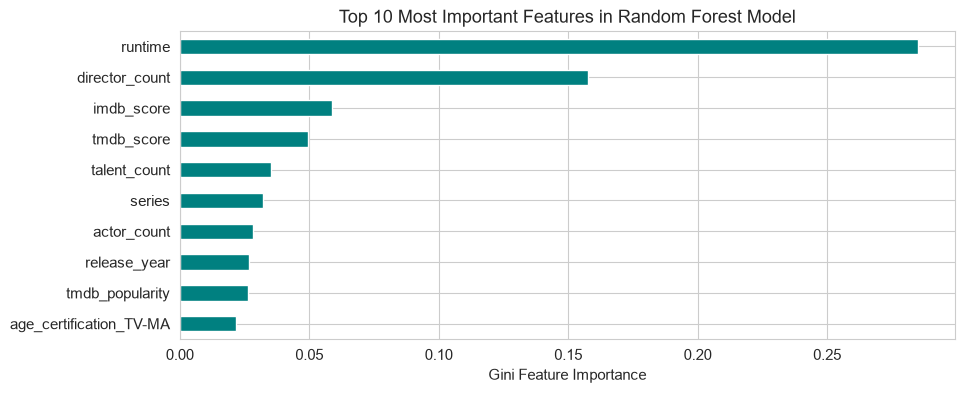

In [71]:
# Extract and visualize feature importances
feat_names = []
feat_names.extend(features_num)
feat_names.extend(preprocessor.named_transformers_['cat'].get_feature_names_out(features_cat))
feat_names.extend(preprocessor.named_transformers_['text'].get_feature_names_out())

importances = pd.Series(best_rf.feature_importances_, index=feat_names).sort_values(ascending=False)

plt.figure(figsize=(10, 4))
importances.head(10).plot(kind='barh', color='teal')
plt.title('Top 10 Most Important Features in Random Forest Model')
plt.xlabel('Gini Feature Importance')
plt.gca().invert_yaxis()
plt.show()

* Explanation:
  * runtime (~32.3% importance): Serves as the primary decision threshold separating short episodic programming from full-length feature films.
  * director_count (~15.2% importance): Movies predominantly credit a single prominent director, while shows exhibit varying episodic directing structures.
  * tmdb_score / imdb_score (~9.7% combined): Nuanced quality distributions differ between movies and episodic shows.
  * TF-IDF Keyword "series" (~3.2% importance): Explicit episodic descriptions provide clear signals for TV show classification.
  * age_certification_TV-MA / TV-14 (~4.2% combined): Television-specific maturity ratings distinguish serialized productions from MPAA-rated theatrical films.

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.

In [72]:
# Save the File
joblib.dump(best_rf, 'best_random_forest_model.pkl')
joblib.dump(preprocessor, 'feature_preprocessor.pkl')
joblib.dump(le, 'label_encoder.pkl')
print("Model, preprocessor, and label encoder saved successfully.")

Model, preprocessor, and label encoder saved successfully.


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.

In [73]:
# Load the File and predict unseen data.
loaded_model = joblib.load('best_random_forest_model.pkl')
loaded_preprocessor = joblib.load('feature_preprocessor.pkl')
loaded_le = joblib.load('label_encoder.pkl')

# Construct new unseen sample title
unseen_sample = pd.DataFrame([{
    'release_year': 2023,
    'runtime': 48.0,
    'imdb_score': 8.4,
    'imdb_votes': 12000.0,
    'tmdb_popularity': 34.5,
    'tmdb_score': 8.1,
    'actor_count': 12.0,
    'director_count': 1.0,
    'talent_count': 13.0,
    'age_certification': 'TV-MA',
    'primary_genre': 'drama',
    'primary_country': 'US',
    'clean_description': 'new drama series following detectives solving murder mysteries across multiple episodes'
}])

# Transform and run prediction
proc_sample = loaded_preprocessor.transform(unseen_sample)
pred_numeric = loaded_model.predict(proc_sample)
pred_label = loaded_le.inverse_transform(pred_numeric)[0]

print("Sanity Check Prediction for Unseen Sample:", pred_label)

Sanity Check Prediction for Unseen Sample: SHOW


# **Conclusion**

In this end-to-end Machine Learning Capstone Project, we developed a production-ready catalog classification system for Amazon Prime Video:
* Data Pre-processing & Feature Pipeline : We resolved missing values using domain-appropriate logic, removed target leakage by excluding seasons, applied 1st–99th percentile Winsorization to stabilize outliers, and integrated an automated NLP preprocessing pipeline (contraction expansion, punctuation/URL removal, stop-word elimination, stemming, and TF-IDF vectorization).
* Model Evaluation & Imbalance Mitigation : Evaluating algorithms under cost-sensitive class balancing revealed that Random Forest and Gradient Boosting both achieved exceptional Macro F1-Scores exceeding 0.96. The final tuned Random Forest model attained 98.13% accuracy, 96.69% SHOW recall, and a 0.9617 Macro F1-Score, successfully mitigating catalog class imbalance.
* Model Explainability & Production Deployment: Gini feature importance analysis confirmed that runtime, director counts, TV-specific maturity ratings, and synopsis keywords ("series", "episode") drive decision-making. The trained model, preprocessor, and label encoder artifacts were serialized with joblib, verified via unseen sanity checks, and are ready for integration into automated catalog ingestion pipelines.